In [ ]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_9/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# Механика стратегий прогнозирования (руками + sktime/ETNA)

Регрессор умеет предсказывать **одно число** по строке признаков. Прогноз на H шагов вперёд —
это H чисел. Как перейти от одного к другому — и есть стратегия прогнозирования.

Все стратегии начинаются одинаково: ряд режется на скользящие окна (**редукция** к табличной
регрессии). Различаются они двумя ответами:

1. **сколько моделей** учим;
2. **что подаём на вход** при прогнозе шага `t+h`: реальные значения, собственные прогнозы или
   только то, что известно на весь горизонт.

| Стратегия | Моделей | Вход при прогнозе | sktime | ETNA |
|---|---|---|---|---|
| рекурсивная | 1 (на шаг +1) | окно + собственные прогнозы | `strategy="recursive"` | `AutoRegressivePipeline` |
| упрощённая прямая | 1 (на все шаги) | признаки, известные на весь горизонт (лаги ≥ H) | `WindowSummarizer` с лагами ≥ H | `Pipeline` |
| прямая | H | одно и то же окно | `strategy="direct"` | `DirectEnsemble` |
| DirRec | H | окно + прогнозы предыдущих моделей | `strategy="dirrec"` | — |
| MIMO | 1 (H выходов) | одно окно | `strategy="multioutput"` | — |
| DIRMO | H/s (по s выходов) | одно окно | — | — |

План: каждую стратегию пишем руками, затем проверяем, что библиотека делает то же самое
(`np.allclose`). Данные — AirPassengers, H = 12, окно W = 12.

In [2]:
import common  # первым: глушит предупреждения библиотек при импорте

common.quiet()

import time  # noqa: E402

import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from catboost import CatBoostRegressor  # noqa: E402
from etna.datasets import TSDataset  # noqa: E402
from etna.ensembles import DirectEnsemble  # noqa: E402
from etna.metrics import MAPE  # noqa: E402
from etna.models import CatBoostPerSegmentModel  # noqa: E402
from etna.pipeline import AutoRegressivePipeline, Pipeline  # noqa: E402
from etna.transforms import LagTransform, LinearTrendTransform  # noqa: E402
from sklearn.multioutput import MultiOutputRegressor  # noqa: E402
from sktime.forecasting.base import ForecastingHorizon  # noqa: E402
from sktime.forecasting.compose import TransformedTargetForecaster, make_reduction  # noqa: E402
from sktime.forecasting.compose._reduce import _sliding_window_transform  # noqa: E402
from sktime.forecasting.trend import PolynomialTrendForecaster  # noqa: E402
from sktime.split import temporal_train_test_split  # noqa: E402
from sktime.transformations.series.detrend import Detrender  # noqa: E402

from common import mape, plot_forecast  # noqa: E402

H, W = 12, 12


def make_catboost(**kwargs):
    return CatBoostRegressor(iterations=300, depth=4, random_seed=0, verbose=False, **kwargs)

## 0. Редукция: ряд → таблица

Нарезку окон делает внутренняя функция sktime `_sliding_window_transform` (приватная — в
своём коде лучше не полагаться на неё, здесь она нужна ради наглядности). На игрушечном ряде
`0, 1, …, 9` с окном W = 4 и горизонтом H = 3:

In [3]:
toy = pd.Series(np.arange(10.0))
yt, Xt = _sliding_window_transform(toy, window_length=4, fh=ForecastingHorizon([1, 2, 3]))
pd.DataFrame(
    np.hstack([Xt, yt]).astype(int),
    columns=["y(t-3)", "y(t-2)", "y(t-1)", "y(t)", "y(t+1)", "y(t+2)", "y(t+3)"],
)

,y(t-3),y(t-2),y(t-1),y(t),y(t+1),y(t+2),y(t+3)
0,0,1,2,3,4,5,6
1,1,2,3,4,5,6,7
2,2,3,4,5,6,7,8
3,3,4,5,6,7,8,9


Каждая строка — одно окно: слева W прошлых значений (признаки `Xt`), справа H будущих
(целевые столбцы `yt`). Все стратегии работают с этой таблицей и отличаются тем, **какие
столбцы `yt` и чем** предсказывают.

### Данные

Урок про деревья: они не экстраполируют, поэтому сначала снимаем линейный тренд — иначе мы будем
сравнивать не стратегии, а то, насколько каждая из них страдает от экстраполяции. Стратегии
руками работают с остатком, тренд прибавляем в конце.

In [4]:
y = common.load_airpassengers()
y_train, y_test = temporal_train_test_split(y, test_size=H)
fh = ForecastingHorizon(np.arange(1, H + 1))

detrender = Detrender(forecaster=PolynomialTrendForecaster(degree=1)).fit(y_train)
resid_train = detrender.transform(y_train)
trend_test = (y_test - detrender.transform(y_test)).to_numpy()  # продолженный тренд на тесте

yt, Xt = _sliding_window_transform(resid_train, window_length=W, fh=fh)
last_window = resid_train.to_numpy()[-W:].reshape(1, -1)  # окно, по которому строим прогноз
print(f"таблица: Xt {Xt.shape}, yt {yt.shape}")

results = {}


def record(name, forecast, n_models, seconds):
    results[name] = {"моделей": n_models, "время, с": seconds, "MAPE": mape(y_test, forecast)}


def sktime_forecaster(strategy, estimator):
    """Та же схема в sktime: Detrender → make_reduction."""
    reduction = make_reduction(estimator, strategy=strategy, window_length=W)
    return TransformedTargetForecaster([Detrender(forecaster=PolynomialTrendForecaster(degree=1)), reduction])

таблица: Xt (109, 12), yt (109, 12)


/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(


## 1. Рекурсивная

Одна модель на шаг вперёд. Для прогноза на H шагов — цикл: предсказали `t+1`, дописали прогноз
в окно, по сдвинутому окну предсказали `t+2`, и так далее.

Модели нужен только столбец `y(t+1)`, поэтому таблицу строим с `fh = [1]` — в ней больше строк,
чем в таблице на 12 шагов (окна не обрезаются на хвосте).

In [5]:
start = time.perf_counter()
yt1, Xt1 = _sliding_window_transform(resid_train, window_length=W, fh=ForecastingHorizon([1]))
model = make_catboost().fit(Xt1, yt1[:, 0])

window = list(last_window.ravel())
recursive = []
for _ in range(H):
    step = model.predict(np.array(window[-W:]).reshape(1, -1))[0]
    recursive.append(step)
    window.append(step)  # собственный прогноз становится «наблюдением»
recursive = np.array(recursive) + trend_test
record("рекурсивная", recursive, 1, time.perf_counter() - start)

library = sktime_forecaster("recursive", make_catboost()).fit(y_train, fh=fh).predict()
print(f"строк в таблице: {len(yt1)} (против {len(yt)} для 12 шагов)")
print(f"руками == sktime: {np.allclose(recursive, library)}")

строк в таблице: 120 (против 109 для 12 шагов)
руками == sktime: True


/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

В ETNA рекурсия — `AutoRegressivePipeline`. Параметр `step` — сколько шагов прогнозируется за одну
итерацию: при `step=3` модель предсказывает три точки по окну, затем дописывает их и двигается
дальше. Лаги при этом должны быть ≥ `step`, иначе на 2-м и 3-м шаге блока признаков ещё нет.
`LinearTrendTransform` — аналог `Detrender`.

In [6]:
frame = pd.DataFrame({"timestamp": y.index.to_timestamp(), "segment": "air", "target": y.to_numpy()})
ts = TSDataset(TSDataset.to_dataset(frame), freq="MS")
train_ts, test_ts = ts.train_test_split(test_size=H)


def etna_catboost():
    return CatBoostPerSegmentModel(iterations=300, depth=4, random_seed=0)


def etna_transforms(first_lag, n_lags=W):
    return [
        LinearTrendTransform(in_column="target"),
        LagTransform(in_column="target", lags=list(range(first_lag, first_lag + n_lags)), out_column="lag"),
    ]


def etna_run(name, pipeline, n_models):
    start = time.perf_counter()
    pipeline.fit(train_ts)
    forecast = pipeline.forecast()
    elapsed = time.perf_counter() - start
    results[name] = {"моделей": n_models, "время, с": elapsed, "MAPE": MAPE()(test_ts, forecast)["air"]}
    return forecast


for step in (1, 3):
    pipeline = AutoRegressivePipeline(etna_catboost(), horizon=H, transforms=etna_transforms(step), step=step)
    etna_run(f"ETNA AutoRegressivePipeline, step={step}", pipeline, 1)
pd.DataFrame(results).T.round(2)

,моделей,"время, с",MAPE
рекурсивная,1.0,0.20,4.68
"ETNA AutoRegressivePipeline, step=1",1.0,0.50,4.60
"ETNA AutoRegressivePipeline, step=3",1.0,0.19,4.70


Цифры ETNA и sktime немного отличаются: у ETNA свой детрендинг и своя нарезка признаков, но
стратегия та же.

## 2. Упрощённая прямая — `Pipeline` в ETNA

Одна модель на **все** шаги горизонта, но в признаках только то, что известно на весь горизонт:
лаги ≥ H. Тогда никакой рекурсии не нужно — для любой точки теста лаг 12 уже есть в истории.

Так устроена «упрощённая прямая» стратегия: все лаги ≥ H. Плата за простоту: для шага `t+1` модель
не видит последних 11 значений — они лежат внутри горизонта.

In [7]:
etna_run("ETNA Pipeline (лаги 12–23)", Pipeline(etna_catboost(), horizon=H, transforms=etna_transforms(H)), 1)
pd.DataFrame(results).T.round(2).tail(1)

,моделей,"время, с",MAPE
ETNA Pipeline (лаги 12–23),1.0,0.15,4.86


## 3. Прямая

H моделей, i-я учится на столбце `y(t+i)` и получает на вход одно и то же последнее окно.
Собственные прогнозы не используются, поэтому ошибка не накапливается — но модели ничего не
знают друг о друге.

In [8]:
start = time.perf_counter()
models = [make_catboost().fit(Xt, yt[:, i]) for i in range(H)]
direct = np.array([m.predict(last_window)[0] for m in models]) + trend_test
record("прямая", direct, H, time.perf_counter() - start)

library = sktime_forecaster("direct", make_catboost()).fit(y_train, fh=fh).predict()
print(f"руками == sktime: {np.allclose(direct, library)}")

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

руками == sktime: True


В ETNA прямая стратегия — `DirectEnsemble`: список пайплайнов с разными горизонтами, каждый
отвечает за «свой» участок. Делать по пайплайну на шаг не обязательно — можно **блоками**:
здесь один пайплайн на шаги 1–6 (лаги ≥ 6, свежее) и второй на 7–12 (лаги ≥ 12).

In [9]:
direct_ensemble = DirectEnsemble(
    pipelines=[
        Pipeline(etna_catboost(), horizon=6, transforms=etna_transforms(6)),
        Pipeline(etna_catboost(), horizon=12, transforms=etna_transforms(12)),
    ],
    n_jobs=1,
    joblib_params={"backend": "threading", "verbose": 0},
)
etna_run("ETNA DirectEnsemble (6 + 12)", direct_ensemble, 2)
pd.DataFrame(results).T.round(2).tail(1)

[Parallel(n_jobs=1)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done   2 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s finished


,моделей,"время, с",MAPE
ETNA DirectEnsemble (6 + 12),2.0,0.31,5.08


## 4. DirRec

Гибрид: H моделей, как в прямой, но i-я модель получает на вход окно **плюс прогнозы моделей
1…i−1**. На обучении на их месте стоят реальные значения `y(t+1)…y(t+i-1)` из таблицы.

In [10]:
start = time.perf_counter()
models = [make_catboost().fit(np.hstack([Xt, yt[:, :i]]), yt[:, i]) for i in range(H)]
window = list(last_window.ravel())
for m in models:
    window.append(m.predict(np.array(window).reshape(1, -1))[0])  # вход растёт на один прогноз
dirrec = np.array(window[W:]) + trend_test
record("DirRec", dirrec, H, time.perf_counter() - start)

library = sktime_forecaster("dirrec", make_catboost()).fit(y_train, fh=fh).predict()
print(f"руками == sktime: {np.allclose(dirrec, library)}")

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

руками == sktime: True


## 5. MIMO

Одна модель, которая предсказывает **вектор** из H значений сразу. В CatBoost для этого есть
`loss_function="MultiRMSE"`: деревья общие для всех выходов, в каждом листе — вектор из H чисел.
Шаги горизонта «согласованы»: модель учит их совместную форму.

In [11]:
start = time.perf_counter()
mimo_model = make_catboost(loss_function="MultiRMSE").fit(Xt, yt)
mimo = mimo_model.predict(last_window).ravel() + trend_test
record("MIMO", mimo, 1, time.perf_counter() - start)

library = sktime_forecaster("multioutput", make_catboost(loss_function="MultiRMSE")).fit(y_train, fh=fh).predict()
print(f"руками == sktime: {np.allclose(mimo, library)}")

руками == sktime: True


/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

**Частая путаница**: `sklearn.multioutput.MultiOutputRegressor` тоже умеет
предсказывать вектор, но внутри это H **независимых** моделей — то есть прямая стратегия:

In [12]:
wrapper = MultiOutputRegressor(make_catboost()).fit(Xt, yt)
print(f"MultiOutputRegressor == прямая: {np.allclose(wrapper.predict(last_window).ravel() + trend_test, direct)}")

MultiOutputRegressor == прямая: True


Настоящий MIMO — только когда сам регрессор умеет многомерный выход (`MultiRMSE` в CatBoost,
`multi_strategy="multi_output_tree"` в XGBoost, нейросети).

## 6. DIRMO — между прямой и MIMO

Горизонт делится на блоки по `s` шагов, на каждый блок — своя MIMO-модель. `s = 1` — это прямая
стратегия, `s = H` — MIMO. Библиотечной реализации в sktime нет, но это несколько строк.

In [13]:
def dirmo(s):
    """H/s MIMO-моделей, каждая на свой блок из s шагов горизонта."""
    blocks = []
    for start in range(0, H, s):
        if s == 1:
            model = make_catboost().fit(Xt, yt[:, start])
        else:
            model = make_catboost(loss_function="MultiRMSE").fit(Xt, yt[:, start : start + s])
        blocks.append(np.atleast_1d(model.predict(last_window).ravel()))
    return np.concatenate(blocks) + trend_test


print(f"s = 1  совпадает с прямой: {np.allclose(dirmo(1), direct)}")
print(f"s = {H} совпадает с MIMO:   {np.allclose(dirmo(H), mimo)}")

start = time.perf_counter()
record("DIRMO, s=6", dirmo(6), H // 6, time.perf_counter() - start)

s = 1  совпадает с прямой: True
s = 12 совпадает с MIMO:   True


## 7. Итоги

In [14]:
summary = pd.DataFrame(results).T
summary["моделей"] = summary["моделей"].astype(int)
summary.round(2)

,моделей,"время, с",MAPE
рекурсивная,1,0.20,4.68
"ETNA AutoRegressivePipeline, step=1",1,0.50,4.60
"ETNA AutoRegressivePipeline, step=3",1,0.19,4.70
ETNA Pipeline (лаги 12–23),1,0.15,4.86
прямая,12,0.60,5.63
ETNA DirectEnsemble (6 + 12),2,0.31,5.08
DirRec,12,0.76,4.82
MIMO,1,0.18,5.34
"DIRMO, s=6",2,0.32,5.28


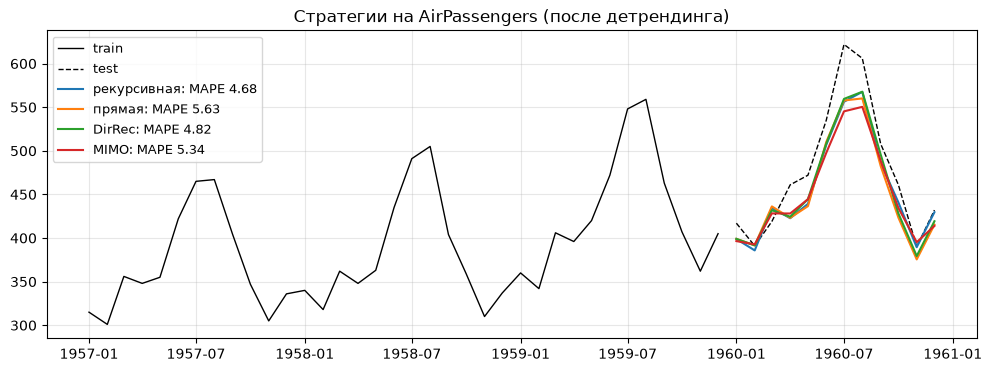

In [15]:
plot_forecast(
    y_train,
    y_test,
    {"рекурсивная": recursive, "прямая": direct, "DirRec": dirrec, "MIMO": mimo},
    last=36,
    title="Стратегии на AirPassengers (после детрендинга)",
);

Насколько важен детрендинг по сравнению с выбором стратегии? Те же рекурсия и MIMO на исходном ряде:

In [16]:
for strategy, estimator in [("recursive", make_catboost()), ("multioutput", make_catboost(loss_function="MultiRMSE"))]:
    raw = make_reduction(estimator, strategy=strategy, window_length=W).fit(y_train, fh=fh).predict()
    print(f"{strategy:12s} без детрендинга: MAPE = {mape(y_test, raw):.2f}")

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

recursive    без детрендинга: MAPE = 5.97
multioutput  без детрендинга: MAPE = 14.53


1. Все стратегии — одна и та же таблица окон; различаются числом моделей и тем, что идёт на вход
   при прогнозе. Ручные реализации совпали с sktime для всех четырёх стратегий.
2. По стоимости: рекурсия, упрощённая прямая и MIMO — одна модель; прямая и DirRec — H моделей
   и в разы дольше.
3. На коротком ряде (120 окон) все стратегии укладываются примерно в 1 п.п. MAPE — на уровне шума.
   Детрендинг меняет результат сильнее, чем выбор стратегии: MIMO без него хуже почти втрое.
4. Различия стратегий проявляются на шумных рядах и длинных горизонтах, а на коротком чистом
   ряде их перекрывает шум.